In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import joblib

# Scikit-learn preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Logistic Regression
from sklearn.linear_model import LogisticRegression

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(DATA_DIR / "train_data.csv")
test_data = pd.read_csv(DATA_DIR / "test_data.csv")

print("Training dataset shape:", train_data.shape)
print("Testing dataset shape:", test_data.shape)

display(train_data.head())

Training dataset shape: (5616, 20)
Testing dataset shape: (1405, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Credit card (automatic),70.70,140.70,Yes
1,Female,0,No,No,15,Yes,Yes,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Credit card (automatic),84.35,1302.65,No
2,Male,0,Yes,Yes,67,Yes,Yes,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.55,6373.10,No
3,Male,0,No,No,5,Yes,No,DSL,No,Yes,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),65.60,339.90,No
4,Male,0,No,No,26,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,20.30,511.25,No


In [3]:
TARGET_COLUMN = "Churn"

X_train = train_data.drop(columns=[TARGET_COLUMN])
y_train = train_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

X_test = test_data.drop(columns=[TARGET_COLUMN])
y_test = test_data[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

X_train: (5616, 19)
y_train: (5616,)
X_test: (1405, 19)
y_test: (1405,)

Training target distribution:
Churn
0    4131
1    1485
Name: count, dtype: int64


In [4]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

print("Numerical features:", numerical_features)
print("Number of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 3

Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 16


In [5]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [6]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [8]:
LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To 

In [9]:
logistic_regression = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=1000,
    random_state=RANDOM_STATE
)

print(logistic_regression)

LogisticRegression(max_iter=1000, penalty='l2', random_state=42)


In [10]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", logistic_regression)
    ]
)

print("Logistic Regression pipeline created!")

Logistic Regression pipeline created!


In [11]:
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [12]:
trained_model = logistic_pipeline.named_steps["classifier"]

print("Number of iterations:", trained_model.n_iter_)

if np.any(trained_model.n_iter_ >= trained_model.max_iter):
    print("Warning: Model may not have converged.")
else:
    print("Model converged successfully!")

Number of iterations: [45]
Model converged successfully!


In [13]:
y_pred = logistic_pipeline.predict(X_test)

y_pred_proba = logistic_pipeline.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Churn_Probability": y_pred_proba
})

display(results.head(10))

,Actual,Predicted,Churn_Probability
0,0,1,0.758962
1,1,1,0.617318
2,1,0,0.284012
3,0,0,0.048976
4,0,0,0.009016
5,0,0,0.327112
6,0,0,0.154226
7,1,1,0.790714
8,0,0,0.017810
9,0,0,0.015024


In [14]:
logistic_metrics = {
    "Model": "Logistic Regression",

    "Accuracy": accuracy_score(y_test, y_pred),

    "AUC": roc_auc_score(y_test, y_pred_proba),

    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),

    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),

    "F1": f1_score(
        y_test, y_pred, zero_division=0
    ),

    "MCC": matthews_corrcoef(y_test, y_pred)
}

logistic_metrics_df = pd.DataFrame([logistic_metrics])

display(
    logistic_metrics_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "MCC": "{:.4f}"
    })
)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8028,0.8403,0.6610,0.5242,0.5847,0.4630


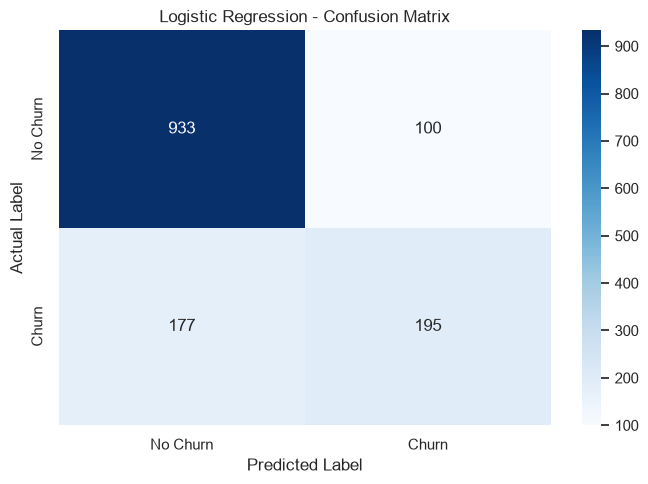

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [16]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn     0.8405    0.9032    0.8707      1033
       Churn     0.6610    0.5242    0.5847       372

    accuracy                         0.8028      1405
   macro avg     0.7508    0.7137    0.7277      1405
weighted avg     0.7930    0.8028    0.7950      1405



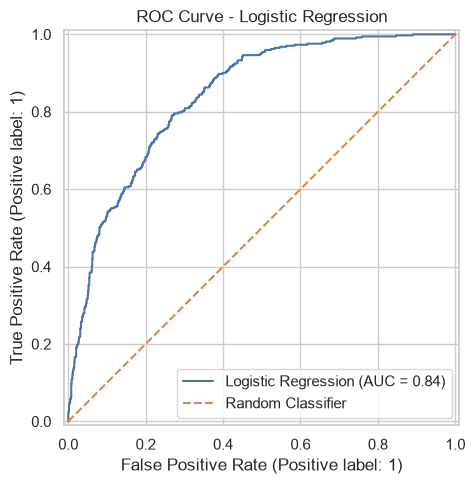

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_pred_proba,
    name="Logistic Regression",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_title("ROC Curve - Logistic Regression")
ax.legend()

plt.tight_layout()
plt.show()

In [18]:
MODEL_PATH = MODEL_DIR / "logistic_regression.joblib"

joblib.dump(logistic_pipeline, MODEL_PATH)

print("Model saved successfully!")
print("Location:", MODEL_PATH)

Model saved successfully!
Location: /Users/walsri/Documents/masters/machine learning/assignments/assignment_2/telecom-customer-churn/models/logistic_regression.joblib


In [19]:
fitted_preprocessor = logistic_pipeline.named_steps["preprocessor"]
fitted_classifier = logistic_pipeline.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

coefficients = fitted_classifier.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

display(coefficient_df.head(15))

,Feature,Coefficient,Absolute_Coefficient
0,num__tenure,-1.383655,1.383655
39,cat__Contract_Two year,-0.768507,0.768507
2,num__TotalCharges,0.643266,0.643266
37,cat__Contract_Month-to-month,0.587737,0.587737
16,cat__InternetService_DSL,-0.551150,0.551150
17,cat__InternetService_Fiber optic,0.523726,0.523726
1,num__MonthlyCharges,-0.311477,0.311477
40,cat__PaperlessBilling_No,-0.300406,0.300406
13,cat__MultipleLines_No,-0.290197,0.290197
5,cat__SeniorCitizen_0,-0.254542,0.254542


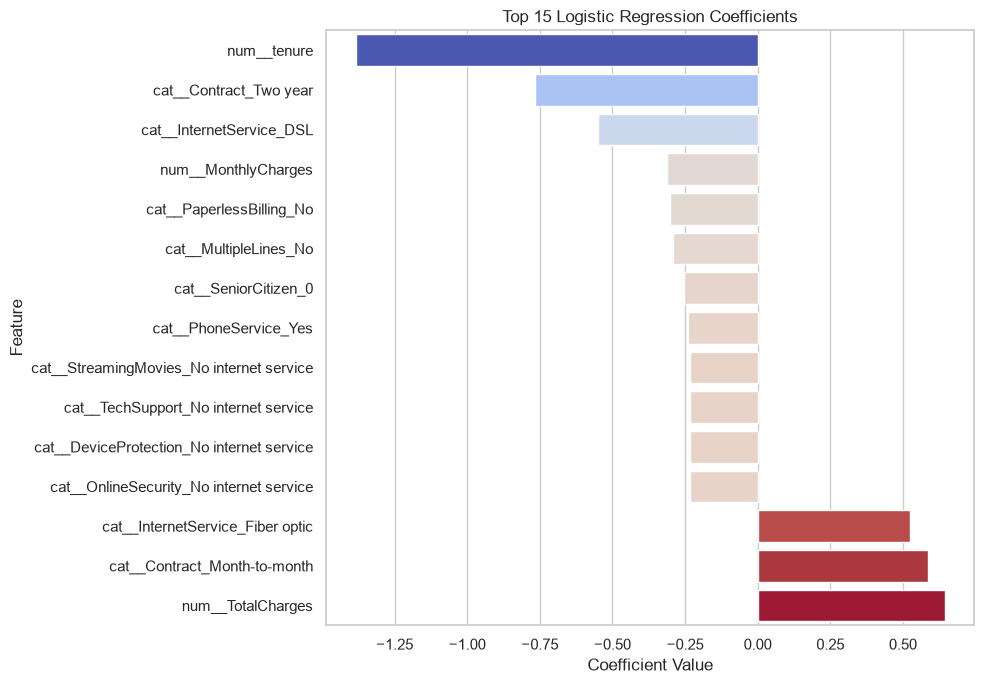

In [20]:
top_coefficients = coefficient_df.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_coefficients,
    x="Coefficient",
    y="Feature",
    hue="Coefficient",
    palette="coolwarm",
    legend=False
)

plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [21]:
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

logistic_metrics_df.to_csv(
    RESULTS_DIR / "logistic_regression_metrics.csv",
    index=False
)

print("Evaluation metrics exported successfully!")

Evaluation metrics exported successfully!
